# Case study 2: Gaia-4 with Gaia DR4 epoch astrometry and radial velocities

This notebook produces the figure, the table and the numbers for Case study 2 of the paper. It mostly follows the `harv` tutorial `docs/tutorials/case-studies/Gaia-4.ipynb`. 

The data are in `../data/Gaia-4/`. This notebook writes the figure `../paper/figures/gaia4-joint.pdf` and the table rows `../paper/tables/gaia4-joint.tex`.

In [1]:
import jax
import numpyro

# Enable float64 before importing harv:
jax.config.update("jax_enable_x64", True)
numpyro.set_host_device_count(4)

In [2]:
from pathlib import Path

import astropy.table as at
import harv
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
from astropy.time import Time
from numpyro.diagnostics import print_summary
from unxt import Q, ustrip

%matplotlib inline
print(f"harv {harv.__version__}, jax {jax.__version__}, numpyro {numpyro.__version__}")
print(jax.devices())

harv 0.0.2.dev258+g9eadbbfe8, jax 0.11.2, numpyro 0.22.0
[CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]


In [3]:
repo_path = Path("..").resolve()
data_path = repo_path / "data" / "Gaia-4"
figure_path = repo_path / "paper" / "figures"
table_path = repo_path / "paper" / "tables"

figure_path.mkdir(exist_ok=True)
table_path.mkdir(exist_ok=True)

## Literature values

The published values that we compare against in the table, as (median, +error, −error). Kanodia et al. (2026) fit the same Gaia DR4 pre-release astrometry jointly with 44 RVs (including 17 HARPS-N RVs that we do not use). Stefansson et al. (2025) fit the Gaia DR3 orbital solution jointly with the RVs we use here.

In [4]:
# Kanodia et al. give i = 120.5 +/- 1.6 deg; we propagate it to cos i:
cos_i_err = np.sin(np.radians(120.5)) * np.radians(1.6)
LITERATURE = {
    # arXiv:2611.15537, Table 1, "This work" column
    "Kanodia et al. (2026)": {
        "period": (575.9, 0.9, 0.9),  # day
        "eccentricity": (0.319, 0.012, 0.012),
        "cos_i": (np.cos(np.radians(120.5)), cos_i_err, cos_i_err),
        "semi_major_axis": (0.250, 0.004, 0.004),  # mas
        "parallax": (13.6251, 0.0074, 0.0074),  # mas
        "rv_semiamp": (315.1, 3.8, 3.8),  # m/s
        "companion_mass": (10.70, 0.32, 0.32),  # Mjup
    },
    # arXiv:2410.05654, Table 2, "Gaia+RV (adopted)" column
    "Stefansson et al. (2025)": {
        "period": (571.3, 1.4, 1.3),
        "eccentricity": (0.338, 0.026, 0.023),
        "cos_i": (-0.452, 0.070, 0.064),
        "semi_major_axis": (0.279, 0.016, 0.014),
        "rv_semiamp": (368.0, 22.0, 18.0),
        "companion_mass": (11.8, 0.73, 0.66),
    },
}
# The stellar mass we adopt, as rounded in the abstract of Stefansson et al. (2025):
M_STAR, M_STAR_ERR = 0.644, 0.02  # Msun

## Loading the data

The astrometry file has one along-scan position per field-of-view transit from the Gaia DR4 pre-release, with times relative to J2017.5 (TCB). The RVs are from Table 5 of Stefansson et al. (2025), from three instruments. We convert the astrometry times to JD so that they share a time axis with the RVs (TCB and TDB differ by about 20 s, which we ignore), and we give all data sets one common reference time, so that the orbital phase parameter means the same thing in each.

In [5]:
gaia_tbl = at.QTable.read(data_path / "Gaia-4.ecsv")
gaia_time = gaia_tbl["relative_time"].to_value("day") + Time("J2017.5", scale="tcb").jd
rv_tbl = at.Table.read(data_path / "Gaia-4-rv.fits")

time_ref = Q(np.mean(np.concatenate([gaia_time, rv_tbl["BJD"]])), "day")

rv_datasets = {}
for inst in np.unique(rv_tbl["Inst"]):
    tmp = rv_tbl[rv_tbl["Inst"] == inst]
    rv_datasets[inst.decode("utf-8").strip()] = harv.RVData(
        time=Q(tmp["BJD"].astype(np.float64), "day"),
        rv=Q(tmp["RVel"].astype(np.float64), "m/s"),
        rv_err=Q(tmp["e_RVel"].astype(np.float64), "m/s"),
        time_ref=time_ref,
    )
rv_data = harv.SourceData(**rv_datasets)

gaia_data = harv.GaiaAstrometryData(
    time=Q(gaia_time, "day"),
    al_position=Q(gaia_tbl["pos_al"].to_value("mas"), "mas"),
    al_position_err=Q(gaia_tbl["pos_al_err"].to_value("mas"), "mas"),
    scan_angle=Q(gaia_tbl["scan_angle"].to_value("deg"), "deg"),
    parallax_factor=np.asarray(gaia_tbl["parallax_factor"], dtype=np.float64),
    time_ref=time_ref,
)

for name, d in {"Gaia transits": gaia_data, **rv_datasets}.items():
    print(f"{name}: {d.n_obs}, spanning {np.ptp(d.time.to_value('day')):.0f} days")

Gaia transits: 93, spanning 1805 days
FIES: 5, spanning 324 days
HPF: 10, spanning 483 days
NEID: 8, spanning 284 days


## Astrometry only: rejection sampling

We use the standard parameterization of the astrometric orbit with the default prior pdfs for the nonlinear parameters, except for the period, which is log-uniform between 10 and 2000 days. The linear parameters have the default Gaussian priors: the reference position has a scale of 100 mas, the proper motion has a scale of 100 km/s in tangential velocity, and the angular semi-major axis of the photocenter orbit has a scale of 1 au at a period of 1 yr. The last two are converted to angles with the catalog parallax (stored in the metadata of the data file) through `scale_parallax`, so they do not depend on the parallax parameter, and the parallax is marginalized like the other linear parameters. This assumes that the orbit does not bias the catalog parallax much, which holds here because the photocenter orbit is small compared with the parallax and the period is not close to 1 yr.

We also set the parallax prior from the catalog parallax, assuming that the orbit is a small perturbation on the apparent motion of the star, using a normal distribution centered on the catalog value with a width of 1 mas, which is broad compared with the size of the orbit. We also include an astrometric jitter, with a half-normal prior with scale 0.1 mas.

We generate $J = 10^7$ prior samples and run the rejection sampler.

In [6]:
catalog_parallax = gaia_tbl.meta["parallax_mas"]
std_prior = harv.models.StandardGaiaAstrometry().default_prior(
    period_min=Q(10.0, "day"),
    period_max=Q(2000.0, "day"),
    sigma_a0=Q(1.0, "AU"),
    sigma_pos=Q(100.0, "mas"),
    sigma_vtan=Q(100.0, "km/s"),
    parallax=harv.QD(dist.TruncatedNormal(catalog_parallax, 1.0, low=0.0), "mas"),
    scale_parallax=Q(catalog_parallax, "mas"),
    jitter=harv.QD(dist.HalfNormal(0.1), "mas"),
)
astrom_model = harv.GaiaAstrometryModel(extensions=(harv.Jitter(obs_unit="mas"),))
marginalized_names = ("ra0", "dec0", "pmra", "pmdec", "parallax", "semi_major_axis")

rejection = harv.RejectionSampler(
    std_prior, astrom_model, marginalized_names=marginalized_names
)
rejection_samples = rejection.run(
    gaia_data,
    key=jax.random.key(1),
    n_prior_samples=10_000_000,
    return_logprobs=True,
    return_evidence_stats=True,
)
print(f"{rejection_samples.n_samples} sample(s) returned")
print(f"J_eff = {float(rejection_samples.metadata['ln_Z_int_ess']):.2f}")
print(f"P = {rejection_samples['period']}")

/var/folders/67/2zgxpmyd2z183j4k6r33nf740000gr/T/ipykernel_981/346094359.py:18: UserWarning: Under-resolved rejection run: the evidence integral is dominated by ~1.0 effective prior sample(s) of 10000000 (below min_evidence_ess=3), so max_ln_likelihood=127.9 may not have converged and the accepted-sample count (1) is not a reliable posterior size. Increase n_prior_samples (compare max_ln_likelihood across runs to check it stops rising) and/or continue with NumpyroSampler(prior, model).run(data, init_samples=...) to draw the posterior.
  rejection_samples = rejection.run(


1 sample(s) returned
J_eff = 1.00
P = Quantity([583.62328592], unit='d')


## Astrometry only: MCMC

We use the returned sample to initialize an optimizer that finds the nearby maximum of the posterior pdf, and then run NUTS from there with 4 chains, with 1000 steps of warm-up and 2000 steps of sampling. `wrap_angles` maps any sample of the sign-flipped orbit ($\omega + \pi$, $\Omega + \pi$, $-a_0$) to $a_0 > 0$ before we summarize the chains.

In [7]:
def chain_summary(s, names):
    # Samples stores the 4 chains one after another.
    print_summary({k: np.asarray(s[k].value).reshape(4, -1) for k in names})


astrom_sampler = harv.NumpyroSampler(
    std_prior, astrom_model, marginalized_names=marginalized_names
)
astrom_opt = astrom_sampler.optimize(
    rejection_samples, gaia_data, key=jax.random.key(0)
)
print(f"optimized: P = {astrom_opt['period']}")
print(f"reduced chi2 = {astrom_opt.reduced_chi2(gaia_data, astrom_model)}")

astrom_mcmc = astrom_sampler.run(
    gaia_data,
    init_samples=astrom_opt,
    key=jax.random.key(123),
    num_chains=4,
    num_warmup=1000,
    num_samples=2000,
    return_logprobs=True,
)
astrom_mcmc = astrom_mcmc.wrap_angles()

orbit_names = ["period", "eccentricity", "cos_i", "semi_major_axis", "parallax"]
chain_summary(astrom_mcmc, [*orbit_names, "jitter"])

optimized: P = Quantity([578.30430489], unit='d')
reduced chi2 = [1.00683345]


  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]


                       mean       std    median      5.0%     95.0%     n_eff     r_hat
           period    577.64      3.73    577.65    571.67    583.94   3959.38      1.00
     eccentricity      0.39      0.08      0.39      0.26      0.52   3892.68      1.00
            cos_i     -0.52      0.04     -0.52     -0.59     -0.45   5517.09      1.00
  semi_major_axis      0.25      0.01      0.25      0.23      0.27   4904.55      1.00
         parallax     13.62      0.01     13.62     13.61     13.64   6941.42      1.00
           jitter      0.02      0.00      0.02      0.01      0.03   4580.74      1.00



## Joint astrometry and RV model

We stack the RVs into one data set and add parameters to model offsets for HPF and NEID relative to FIES, which are linear parameters and are marginalized, and an RV jitter, which is shared by the three instruments. The joint model shares the orbital parameters between the RVs and the astrometry, and because the companion is unseen, the RV semi-amplitude is tied to the astrometric orbit and the parallax. Because the tie depends on the parallax, harv samples the parallax in the joint model (the prior widths still come from the catalog parallax).

The astrometry alone cannot distinguish the orbit from its mirror image ($\omega \to \omega + \pi$, $\Omega \to \Omega + \pi$), so we optimize the joint posterior pdf starting from both the astrometry-only maximum a posteriori sample and its mirror, and run NUTS from the one with the larger posterior probability.

In [8]:
rv_data_merged, indicator, instrument_names = rv_data.indicator_data_by_type(
    harv.RVData, reference="FIES"
)
rv_model = harv.RVModel(
    extensions=(
        harv.Jitter(obs_unit="m/s"),
        harv.MultiSurveyOffset(indicator, instrument_names, "m/s"),
    )
)
joint_model = harv.JointModel.for_rv_and_gaia(
    components={"rv": rv_model, "astrom": astrom_model}
)
joint_prior = harv.HarvPrior(
    nonlinear_priors=std_prior.nonlinear_priors,
    linear_priors={
        "rv.v_sys": harv.QD(dist.Normal(0.0, 1.0), "km/s"),
        **{f"astrom.{k}": v for k, v in std_prior.linear_priors.items()},
    },
    extension_priors={
        "astrom.jitter": std_prior.extension_priors["jitter"],
        "rv.jitter": harv.QD(dist.HalfNormal(20.0), "m/s"),
        "rv.HPF": harv.QD(dist.Normal(0.0, 100.0), "m/s"),
        "rv.NEID": harv.QD(dist.Normal(0.0, 100.0), "m/s"),
    },
)
joint_data = harv.SourceData(rv=rv_data_merged, astrom=gaia_data)

In [9]:
joint_sampler = harv.NumpyroSampler(joint_prior, joint_model)
candidates = astrom_mcmc.map_sample().with_astrometric_mirror()
joint_init = joint_sampler.optimize(candidates, joint_data, key=jax.random.key(345))
# with_astrometric_mirror puts the original sample first and its mirror second.
ln_post = np.asarray(joint_init.ln_posterior)
print(f"ln posterior: sample {ln_post[0]:.1f}, mirror {ln_post[1]:.1f}")

joint_mcmc = joint_sampler.run(
    joint_data,
    init_samples=joint_init.map_sample(),
    key=jax.random.key(789),
    num_chains=4,
    num_warmup=1000,
    num_samples=2000,
    return_logprobs=True,
)
joint_mcmc = joint_mcmc.wrap_angles()

rv_names = ["rv_semiamp", "HPF", "NEID", "rv.jitter"]
chain_summary(joint_mcmc, [*orbit_names, "astrom.jitter", *rv_names])

ln posterior: sample -73.6, mirror 8.8


  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]


                       mean       std    median      5.0%     95.0%     n_eff     r_hat
           period    575.64      1.12    575.63    573.70    577.39   6726.27      1.00
     eccentricity      0.32      0.02      0.32      0.29      0.36   6204.25      1.00
            cos_i     -0.50      0.03     -0.50     -0.55     -0.45   5342.93      1.00
  semi_major_axis      0.25      0.01      0.25      0.24      0.26   7425.68      1.00
         parallax     13.63      0.01     13.63     13.61     13.64   8398.92      1.00
    astrom.jitter      0.02      0.00      0.02      0.01      0.03   5321.64      1.00
       rv_semiamp    322.01     10.16    321.89    305.45    338.42   5428.50      1.00
              HPF   -115.08     15.36   -115.42   -139.39    -89.98   7463.41      1.00
             NEID    -98.80     14.99    -99.17   -121.65    -73.16   6957.23      1.00
        rv.jitter     21.81      5.26     21.27     12.93     29.33   5663.60      1.00



## Table

We summarize both chains by the median and the 16th and 84th percentiles. For the companion mass, we draw a stellar mass from $\mathcal{N}(0.644, 0.02)~M_\odot$ for each sample. The table rows give "median +upper −lower" when the two sides of the interval differ by more than 10 percent, and "median ± sigma" otherwise, with two significant figures in the uncertainty.

In [10]:
def interval(q, unit=""):
    lo, med, hi = np.percentile(ustrip(unit, q), [16, 50, 84])
    return med, hi - med, med - lo


rng = np.random.default_rng(42)
columns = {}
for name, s, astrom_part in [
    ("astrometry only", astrom_mcmc, astrom_mcmc),
    ("joint", joint_mcmc, joint_mcmc.component("astrom")),
]:
    m_star = Q(rng.normal(M_STAR, M_STAR_ERR, s.n_samples), "Msun")
    columns[name] = {
        "period": interval(s["period"], "day"),
        "eccentricity": interval(s["eccentricity"]),
        "cos_i": interval(s["cos_i"]),
        "semi_major_axis": interval(s["semi_major_axis"], "mas"),
        "parallax": interval(s["parallax"], "mas"),
        "companion_mass": interval(astrom_part.companion_mass(m_star), "Mjup"),
    }
columns["joint"]["rv_semiamp"] = interval(joint_mcmc["rv_semiamp"], "m/s")
columns |= LITERATURE

for k in ["period", "eccentricity"]:
    ratio = np.std(astrom_mcmc[k].value) / np.std(joint_mcmc[k].value)
    print(f"{k}: the joint posterior is {ratio:.1f} times narrower")

period: the joint posterior is 3.3 times narrower
eccentricity: the joint posterior is 3.7 times narrower


In [11]:
def fmt(med, plus, minus):
    sigma = (plus + minus) / 2
    asymmetric = abs(plus - minus) > 0.1 * sigma
    # 2 significant figures in the smallest uncertainty shown (rounded first, so that
    # e.g. 9.98 becomes 10, not 10.0):
    err = float(f"{min(plus, minus) if asymmetric else sigma:.2g}")
    nd = max(0, 1 - int(np.floor(np.log10(err))))
    if asymmetric:
        return f"${med:.{nd}f}^{{+{plus:.{nd}f}}}_{{-{minus:.{nd}f}}}$"
    return f"${med:.{nd}f} \\pm {sigma:.{nd}f}$"


ROWS = {
    "period": "$P$ [\\unit{day}]",
    "eccentricity": "$e$",
    "cos_i": "$\\cos i$",
    "semi_major_axis": "$a_0$ [\\unit{mas}]",
    "parallax": "$\\varpi$ [\\unit{mas}]",
    "rv_semiamp": "$K$ [\\unit{m.s^{-1}}]",
    "companion_mass": "$M_{\\rm p}$ [\\unit{\\Mjup}]",
}
lines = [
    " & ".join(
        [label, *(fmt(*c[k]) if k in c else "\\nodata" for c in columns.values())]
    )
    + " \\\\"
    for k, label in ROWS.items()
]
(table_path / "cs2-gaia4-joint.tex").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

$P$ [\unit{day}] & $577.6 \pm 3.7$ & $575.6 \pm 1.1$ & $575.90 \pm 0.90$ & $571.3 \pm 1.4$ \\
$e$ & $0.386 \pm 0.077$ & $0.324 \pm 0.020$ & $0.319 \pm 0.012$ & $0.338^{+0.026}_{-0.023}$ \\
$\cos i$ & $-0.519 \pm 0.043$ & $-0.500 \pm 0.031$ & $-0.508 \pm 0.024$ & $-0.452 \pm 0.067$ \\
$a_0$ [\unit{mas}] & $0.252 \pm 0.011$ & $0.2534 \pm 0.0061$ & $0.2500 \pm 0.0040$ & $0.279^{+0.016}_{-0.014}$ \\
$\varpi$ [\unit{mas}] & $13.6246 \pm 0.0081$ & $13.6254 \pm 0.0079$ & $13.6251 \pm 0.0074$ & \nodata \\
$K$ [\unit{m.s^{-1}}] & \nodata & $321.9 \pm 9.9$ & $315.1 \pm 3.8$ & $368^{+22}_{-18}$ \\
$M_{\rm p}$ [\unit{\Mjup}] & $10.77 \pm 0.50$ & $10.84 \pm 0.35$ & $10.70 \pm 0.32$ & $11.80^{+0.73}_{-0.66}$ \\


## Figure

All three panels use the joint chain:
- **Left:** the along-scan positions, minus the position, proper motion and parallax terms of the best-fit model, against orbital phase. Next to them is the best-fit orbital term at the same epochs. The model predicts the data as a sum of linear terms, and terms missing from `linear_values` are set to zero, so the orbital term is the prediction with only the semi-major axis kept. The orbital term is not a smooth curve, because the scan angle changes from transit to transit.
- **Middle:** the photocenter orbit on the sky for 128 posterior samples, from `predict_orbit_sky` (which `harv.plot.plot_gaia_sky_orbit` uses for one sample).
- **Right:** the RVs, with RV curves for the same 128 samples.

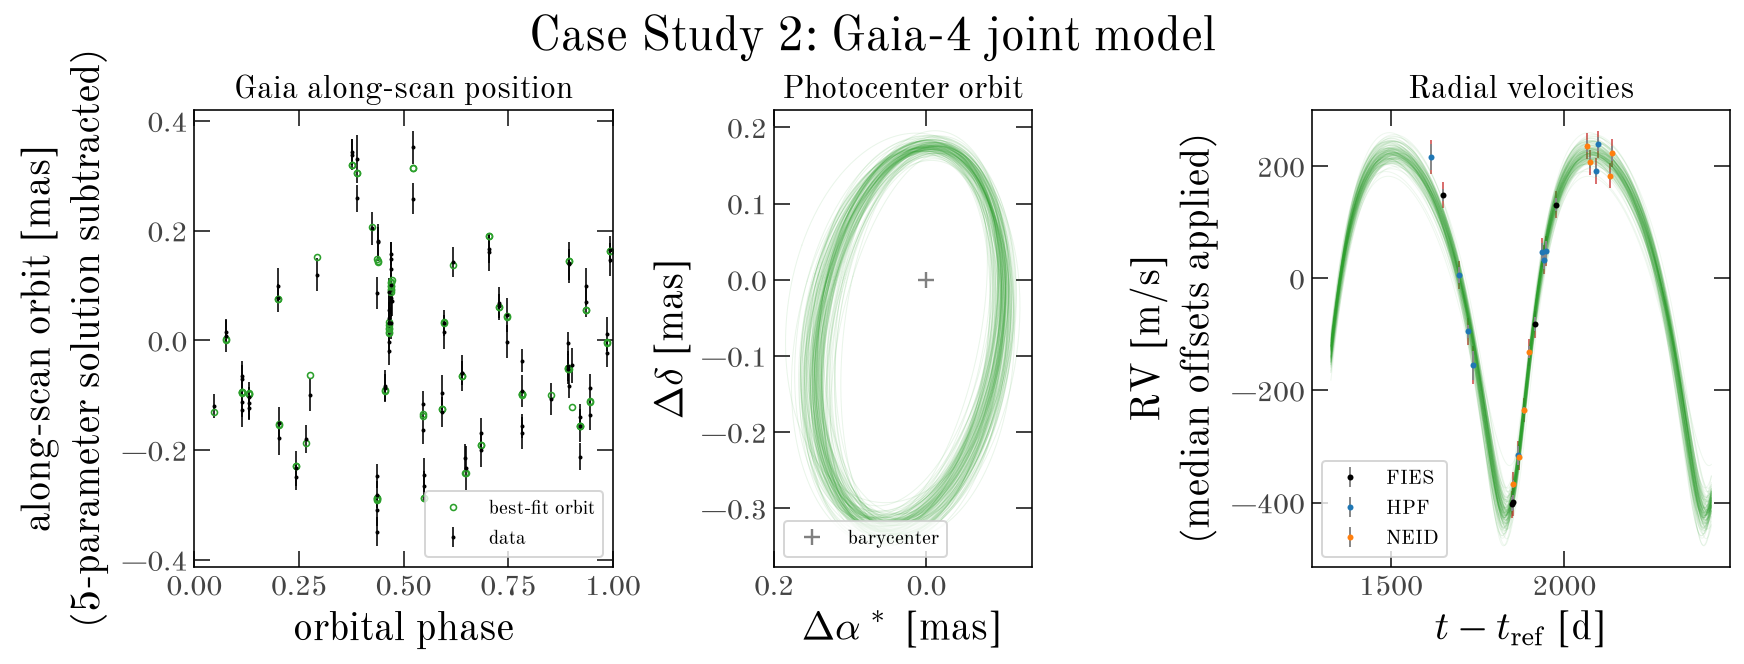

In [14]:
def params(s):
    # The nonlinear and linear values of a single sample, as the model's predict
    # methods take them; linear parameters left out are set to zero.
    return {k: v[0] for k, v in s.nonlinear.items()}, {
        k: v.value[0] for k, v in s.linear.items()
    }


# A random subset of samples: plot_rv draws the first rows, and the chains are stored
# one after another.
rng = np.random.default_rng(42)
shuffled = joint_mcmc[rng.permutation(joint_mcmc.n_samples)]

# The best-fit model: optimizing the MAP sample sets the linear parameters to their
# conditional mean (in the chain they are random draws).
best_fit = joint_sampler.optimize(
    joint_mcmc.map_sample(), joint_data, key=jax.random.key(345)
).component("astrom")

fig, (ax_al, ax_sky, ax_rv) = plt.subplots(
    1, 3, figsize=(12, 4.5), layout="constrained"
)

# Left: along-scan positions without the non-orbital terms of the best-fit model.
nl, lin = params(best_fit)
full = np.asarray(astrom_model.predict(nl, lin, gaia_data))
orbit = np.asarray(
    astrom_model.predict(nl, {"semi_major_axis": lin["semi_major_axis"]}, gaia_data)
)
period = best_fit["period"].to_value("day")[0]
phase = ((gaia_time - best_fit["time_peri"].to_value("day")[0]) / period) % 1
ax_al.errorbar(
    phase,
    gaia_data.al_position.to_value("mas") - (full - orbit),
    gaia_data.al_position_err.to_value("mas"),
    fmt="o", ms=2, lw=0.8, color="k", label="data",
)  # fmt: skip
ax_al.plot(
    phase,
    orbit,
    "o",
    ms=3,
    mfc="none",
    mew=0.8,
    color="tab:green",
    label="best-fit orbit",
)
ax_al.set(
    xlim=(0, 1),
    xlabel="orbital phase",
    ylabel="along-scan orbit [mas]\n(5-parameter solution subtracted)",
)
ax_al.legend(loc="best")

# Middle: photocenter orbit on the sky, over one period of each sample.
for i in range(128):
    s = shuffled[i].component("astrom")
    nl, lin = params(s)
    times = Q(np.linspace(0, s["period"].to_value("day")[0], 256), "day")
    dra, ddec = astrom_model.predict_orbit_sky(nl, lin, times)
    ax_sky.plot(dra, ddec, "-", color="tab:green", alpha=0.1, lw=0.5, rasterized=True)
ax_sky.plot(0, 0, "+", color="0.5", ms=8, mew=1.2, label="barycenter")
ax_sky.set(
    aspect="equal", xlabel=r"$\Delta\alpha^*$ [mas]", ylabel=r"$\Delta\delta$ [mas]"
)
ax_sky.invert_xaxis()  # east to the left
ax_sky.legend(loc="lower left")

# Right: RVs with median offsets, and RV curves for the same 128 samples.
harv.plot.plot_rv(
    shuffled.component("rv"),
    data=rv_data,
    model=rv_model,
    n_samples=128,
    relative_to_time_ref=True,
    relative_to_median_v_sys=True,
    apply_median_offsets=True,
    plot_kwargs={"color": "tab:green"},
    ax=ax_rv,
)
ax_rv.set(
    title="",
    xlabel=r"$t - t_{\rm ref}$ [d]",
    ylabel="RV [m/s]\n(median offsets applied)",
)

fig.suptitle("Case Study 2: Gaia-4 joint model", fontsize=24)
ax_rv.set_title("Radial velocities", fontsize=16)
ax_al.set_title("Gaia along-scan position", fontsize=16)
ax_sky.set_title("Photocenter orbit", fontsize=16)

fig.savefig(figure_path / "gaia4-joint.pdf", dpi=300)